In [4]:
import pandas as pd
import numpy as np
# from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

In [10]:
RESULT_DIR = Path("../results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")
node_importance_file = RESULT_DIR / "atob_nc005nd.csv"
result_file = RESULT_DIR / "explanations_attributes_object.pth"

In [8]:
df = pd.read_csv(node_importance_file)
df

,node,word,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,0,a,180,10,0.055556,178,6,0.033708,-0.021848
1,1,about,180,1,0.005556,178,11,0.061798,0.056242
2,2,above,180,19,0.105556,178,11,0.061798,-0.043758
3,4,after,180,0,0.000000,178,18,0.101124,0.101124
4,5,afterwards,180,41,0.227778,178,17,0.095506,-0.132272
...,...,...,...,...,...,...,...,...,...
81,108,in,180,57,0.316667,178,25,0.140449,-0.176217
82,109,indeed,180,10,0.055556,178,18,0.101124,0.045568
83,111,instead,180,27,0.150000,178,12,0.067416,-0.082584
84,112,into,180,17,0.094444,178,9,0.050562,-0.043883


In [11]:
results = torch.load(
    result_file,
    map_location="cpu",
    weights_only=False
)

In [14]:
def get_node_importance(node_mask):
    """
    Convert node_mask into node importance if needed. 
    """
    if node_mask is None:
        return None

    mask = torch.as_tensor(node_mask).detach().cpu()

    if mask.ndim == 2:
        return mask.mean(dim=1)

    if mask.ndim == 1:
        return mask

    raise ValueError(f"Unexpected node mask shape {mask.shape}")

In [17]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float))

    n = len(values)

    if n == 0:
        return np.nan

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def analyze_node_uniformity(results):

    rows = []

    for result in results:

        node_mask = result["node_mask"]

        if node_mask is None:
            continue

        importance = get_node_importance(node_mask)

        if importance is None:
            continue

        importance = torch.as_tensor(importance).detach().cpu().numpy()

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",
            "mean": np.mean(importance),
            "std": np.std(importance),
            "gini": gini_coefficient(importance),
            "p90_p10": (
                np.percentile(importance, 90)
                - np.percentile(importance, 10)
            ),
        })

    df = pd.DataFrame(rows)

    print("\nSummary across graphs:")
    print(
        df[["mean", "std", "gini", "p90_p10"]]
        .describe()
        .round(3)
    )

    return df

In [18]:
df_uniform = analyze_node_uniformity(results)


Summary across graphs:
          mean      std     gini  p90_p10
count  360.000  360.000  360.000  360.000
mean     0.196    0.018    0.045    0.045
std      0.074    0.014    0.029    0.037
min      0.141    0.002    0.006    0.004
25%      0.148    0.005    0.019    0.012
50%      0.160    0.012    0.039    0.031
75%      0.217    0.031    0.071    0.083
max      0.440    0.046    0.101    0.120


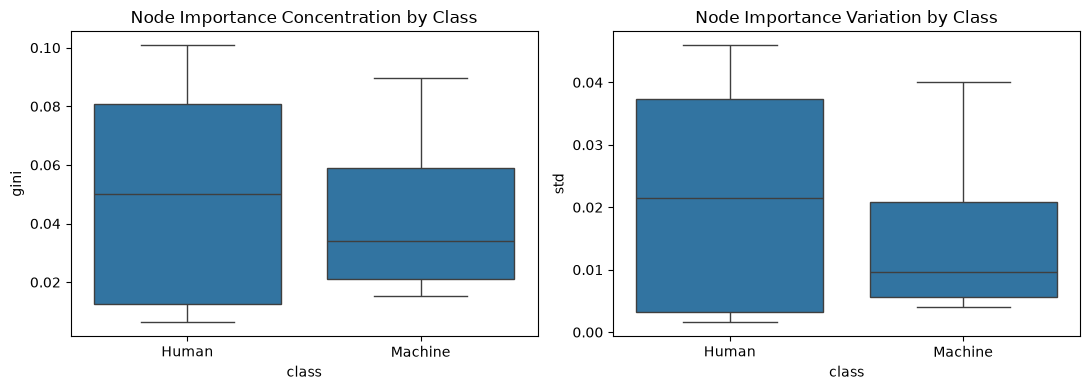

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=df_uniform,
    x="class",
    y="gini",
    ax=axes[0]
)

axes[0].set_title("Node Importance Concentration by Class")

sns.boxplot(
    data=df_uniform,
    x="class",
    y="std",
    ax=axes[1]
)

axes[1].set_title("Node Importance Variation by Class")

plt.tight_layout()
plt.show()

In [20]:
import numpy as np
import pandas as pd
import torch


def aggregate_feature_importance(results, correct_only=True):
    """
    Aggregate GNNExplainer node feature masks into
    count, frequency, and embedding importance.

    Assumes:
        Feature 0 = count
        Feature 1 = frequency
        Features 2: = embeddings
    """

    rows = []

    if isinstance(results, pd.DataFrame):
        records = results.to_dict("records")
    else:
        records = results

    for result in records:

        if correct_only and result["label"] != result["pred"]:
            continue

        node_mask = result["node_mask"]

        if node_mask is None:
            continue

        mask = torch.as_tensor(node_mask).detach().cpu().numpy()

        if mask.ndim != 2 or mask.shape[1] < 3:
            raise ValueError(
                f"Unexpected node mask shape: {mask.shape}"
            )

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",

            "count": mask[:, 0].mean(),
            "frequency": mask[:, 1].mean(),
            "embedding": mask[:, 2:].mean(),

            # Variation within each feature group
            "count_std": mask[:, 0].std(),
            "frequency_std": mask[:, 1].std(),
            "embedding_std": mask[:, 2:].std(),
        })

    return pd.DataFrame(rows)

In [22]:
df_features = aggregate_feature_importance(results, correct_only=True)
df_features

,row,class,count,frequency,embedding,count_std,frequency_std,embedding_std
0,13,Human,0.185410,0.187370,0.375819,0.248147,0.251081,0.115879
1,17,Human,0.249234,0.218167,0.214365,0.233867,0.213516,0.085646
2,20,Human,0.163828,0.145593,0.174833,0.221661,0.205918,0.055207
3,22,Human,0.224603,0.201301,0.230924,0.248371,0.226739,0.095695
4,28,Human,0.126004,0.097626,0.145147,0.145649,0.118301,0.012089
...,...,...,...,...,...,...,...,...
353,2372,Machine,0.052213,0.049147,0.155395,0.101076,0.094437,0.043937
354,2379,Machine,0.130336,0.113369,0.188801,0.179627,0.160397,0.073963
355,2381,Machine,0.139831,0.110995,0.173830,0.160572,0.130401,0.062325
356,2383,Machine,0.056776,0.049196,0.150611,0.081065,0.070055,0.043976


In [23]:
def plot_feature_importance(df_features):

    plot_df = df_features.melt(
        id_vars=["row", "class"],
        value_vars=["count", "frequency", "embedding"],
        var_name="Feature group",
        value_name="Importance",
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Overall importance
    sns.boxplot(
        data=plot_df,
        x="Feature group",
        y="Importance",
        ax=axes[0],
    )

    axes[0].set_title("Feature Importance Across Graphs")
    axes[0].set_ylabel("Mean GNNExplainer mask value")

    # Comparison between classes
    sns.boxplot(
        data=plot_df,
        x="Feature group",
        y="Importance",
        hue="class",
        ax=axes[1],
    )

    axes[1].set_title("Feature Importance by Class")
    axes[1].set_ylabel("Mean GNNExplainer mask value")

    plt.tight_layout()
    plt.show()

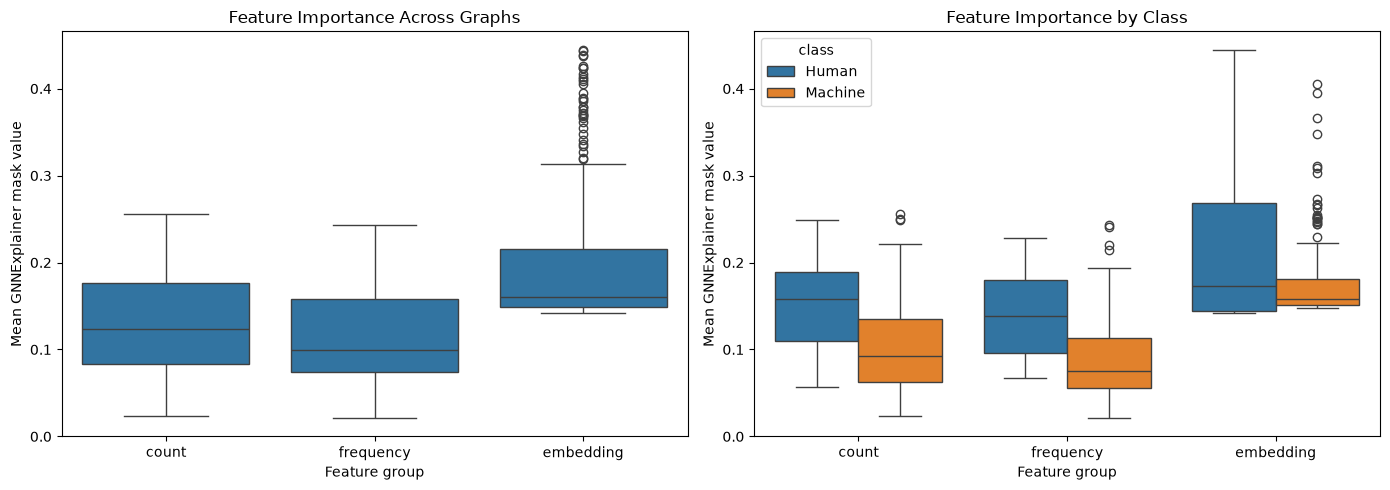

In [24]:
plot_feature_importance(df_features)

In [25]:
def gini_coefficient(values):
    values = np.sort(np.asarray(values, dtype=float).flatten())

    n = len(values)

    if n == 0 or not np.all(np.isfinite(values)):
        return np.nan

    if np.any(values < 0):
        raise ValueError("Gini requires nonnegative values.")

    if np.sum(values) == 0:
        return 0.0

    return (
        2 * np.sum(np.arange(1, n + 1) * values)
        / (n * np.sum(values))
        - (n + 1) / n
    )


def analyze_feature_uniformity(results, correct_only=True):

    rows = []

    for result in results:

        if correct_only and result["label"] != result["pred"]:
            continue

        mask = torch.as_tensor(
            result["node_mask"]
        ).detach().cpu().numpy()

        # Mean importance per feature dimension
        feature_importance = mask.mean(axis=0)

        rows.append({
            "row": result["row"],
            "class": "Human" if result["label"] == 0 else "Machine",
            "gini": gini_coefficient(feature_importance),
            "std": feature_importance.std(),
            "p90_p10": (
                np.percentile(feature_importance, 90)
                - np.percentile(feature_importance, 10)
            ),
        })

    return pd.DataFrame(rows)

In [26]:
df_un_feat = analyze_feature_uniformity(results)
df_un_feat

,row,class,gini,std,p90_p10
0,13,Human,0.073244,0.050296,0.116699
1,17,Human,0.117148,0.048378,0.111257
2,20,Human,0.081507,0.031140,0.058267
3,22,Human,0.115751,0.050532,0.118619
4,28,Human,0.016393,0.006821,0.006664
...,...,...,...,...,...
353,2372,Machine,0.068416,0.034933,0.017362
354,2379,Machine,0.112816,0.050601,0.068015
355,2381,Machine,0.097809,0.045541,0.048748
356,2383,Machine,0.059485,0.034973,0.013006


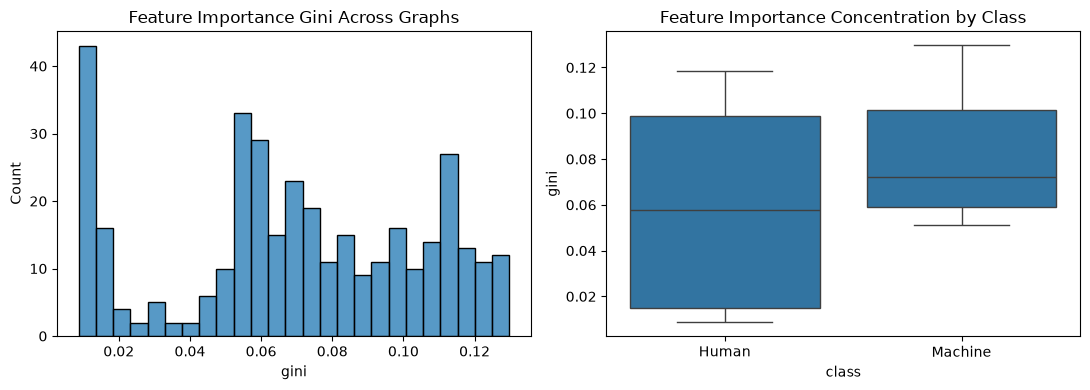

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(
    data=df_un_feat,
    x="gini",
    bins=25,
    ax=axes[0],
)

axes[0].set_title("Feature Importance Gini Across Graphs")

sns.boxplot(
    data=df_un_feat,
    x="class",
    y="gini",
    ax=axes[1],
)

axes[1].set_title("Feature Importance Concentration by Class")

plt.tight_layout()
plt.show()